# Spatial Encoding

**Part:** F – Image formation · **Reading time:** ~60 min · **Pass 1 overview:** [From Signal to Image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

**Why this chapter matters.** The receive coil hears *one* voltage: the sum of the signals of all spins in the body. Nothing in that sum says *where* a signal came from. Spatial encoding is the trick that makes position audible: magnetic field **gradients** give every location its own precession frequency (frequency encoding) or its own phase (phase encoding). Once position is written into frequency/phase, a Fourier transform reads it back out, and we get an image. Everything later in Part F and G (k-space, reconstruction, FOV, resolution, SNR, scan time) is built on the two ideas of this chapter.

## Learning goals

1. Describe how images are formed
    * Describe the effects of gradients on the signal
    * Understand how frequency encoding works — and derive $x = f/(\bar\gamma G_{x,r})$
    * Understand how phase encoding works — and derive the phase $\Phi(n)$ of the $n$-th phase-encoding step
2. Explain why frequency encoding gets a whole line of data in one readout, whereas phase encoding needs one repetition (one TR) per line
3. Read a Cartesian 2D FT pulse sequence diagram and compute realistic gradient amplitudes for it
4. Simulate (in Python) the signal of a frequency-encoded 1D object and a frequency+phase-encoded 2D object and reconstruct them

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position (z along $B_0$) | m | object size ~0.1–0.4 m |
| $t$, $\tau$ | time; $\tau$ = dummy integration variable | s | |
| $B_0$ | main static field (along z) | T | 1.5 T, 3 T |
| $B_z(\vec r,t)$ | z-component of the magnetic field at $\vec r$ | T | $B_0+\vec G\cdot\vec r$ |
| $\Delta B_z$ | change of $B_z$ caused by the gradient | T | ~mT across the body |
| $\vec G=[G_x,G_y,G_z]^T$ | gradient: rate of change of $B_z$ with position | T/m | 10–80 mT/m |
| $G_{x,r}$ | readout (frequency-encoding) gradient amplitude (figure: $G_{xr}$) | T/m | 2–30 mT/m |
| $G_{y,PE}$ | largest phase-encoding gradient amplitude (figure/original: $G_{yp}$) | T/m | ~5–30 mT/m |
| $G_{yi}$ | increment of the phase-encoding amplitude between steps | T/m | ~0.1 mT/m |
| $G_y^{(n)}$ | phase-encoding amplitude used in step $n$ | T/m | $-G_{y,PE}+(n-1)G_{yi}$ |
| $t_y$ | duration of the phase-encoding gradient lobe | s | 0.5–2 ms |
| $n$ | phase-encoding step index | – | $1,\dots,N_{PE}$ |
| $N_{PE}$, $N_{read}$ | number of phase-encoding steps; number of readout samples | – | 128–512 |
| $\gamma$ | gyromagnetic ratio (angular) | rad s⁻¹ T⁻¹ | $2.675\times10^8$ (¹H) |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | Hz/T | 42.58 MHz/T (¹H) |
| $f_0=\bar\gamma B_0$ | Larmor frequency | Hz | 127.7 MHz @ 3 T |
| $f(\vec r)$ | precession frequency **relative to** $f_0$ (rotating frame) | Hz | ±10–100 kHz across the body |
| $\omega=2\pi f$ | angular frequency | rad/s | |
| $\phi$, $\Phi$ | phase of $M_{xy}$ | rad | |
| $M_{xy}=M_x+iM_y$ | transverse magnetization (complex, rotating frame) | normalized ($M_0=1$) | |
| $m(\vec r)$ | transverse magnetization right after excitation = the "image" we want | a.u. | |
| $s(t)$, $s_n(t)$ | received (demodulated) signal; in phase-encoding step $n$ | V (a.u.) | |
| $k_x$, $k_y$ | spatial frequency ("k-space position") | m⁻¹ (cycles/m) | ±100–1000 m⁻¹ |
| $\Delta k$ | spacing of k-space samples | m⁻¹ | $1/FOV$ |
| $FOV$ | field of view (size of the image) | m | 0.24 m |
| $\delta$ | pixel size (spatial resolution) | m | ~1 mm |
| $\Delta t$ | dwell time (time between two ADC samples) | s | 2–20 µs |
| $BW_{read}=1/\Delta t$ | total readout (receiver) bandwidth (figure: $RBW$, and $\Delta T_s=\Delta t$) | Hz | 16–500 kHz |
| $T_{read}=N_{read}\Delta t$ | readout duration | s | 2–10 ms |
| $TE$, $TR$ | echo time, repetition time | s | TE 2–100 ms, TR 5 ms–5 s |
| $NEX$ | number of averages | – | 1–4 |
| $T_{scan}$ | total scan time | s | |
| $\theta$, $T_{rf}$, $TBW_{rf}$ | flip angle, RF duration, RF time-bandwidth product | rad, s, – | |
| $G_{z,SS}$ | slice-select gradient | T/m | |
| $L$ | length of the object along the frequency-encoding axis | m | |
| $i$ | imaginary unit $\sqrt{-1}$ | – | |

> **⚠️ Common confusion:** in this chapter $M_{xy}$ is the **transverse magnetization**. In the next chapter Larson also uses $M(\vec k)$ for **k-space data**; whenever $M$ appears we say which one is meant.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Effects of magnetic field gradients

The magnet produces a field $B_0$ along $z$ that is (ideally) the same everywhere. **Gradient coils** (three of them: x, y and z; see [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)) add a small extra $z$-field that **changes linearly with position**:

$$\Delta B_z(\vec r) = \vec{G}\cdot\vec{r} = G_x x + G_y y + G_z z$$

In words: the extra field is zero at the scanner's center (isocenter, $\vec r = 0$) and grows in proportion to the distance along the gradient direction.

where
* $\Delta B_z$ [T] is the change of the z-component of the field,
* $\vec G = [G_x,G_y,G_z]^T$ [T/m] is the gradient vector; $G_x$ is "how many tesla per metre $B_z$ increases when you move along $x$",
* $\vec r = [x,y,z]^T$ [m] is the position.

So the total field along $z$ is $B_z(\vec r) = B_0 + \vec G\cdot\vec r$, and by the Larmor relation the precession frequency becomes $\bar\gamma(B_0+\vec G\cdot\vec r)$. We almost always work in the **rotating frame** — a coordinate system that itself rotates at $f_0=\bar\gamma B_0$ (in hardware: the receiver *demodulates* the signal by $f_0$; see [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)). In the rotating frame only the *extra* frequency is left:

$$ f(\vec r) = \bar \gamma \ \vec{G}\cdot\vec{r} $$

In words: with a gradient switched on, **the precession frequency is a linear function of position**. This is the basis of all spatial encoding: position is encoded in the frequency (and, integrated over time, in the phase) of the transverse magnetization.

where $f(\vec r)$ [Hz] is the frequency relative to $f_0$ and $\bar\gamma = 42.58$ MHz/T for ¹H.

> **⚠️ Common confusion:** a "gradient" in MRI does *not* tilt the field direction. The field still points (essentially) along $z$; only its *strength* $B_z$ varies with position. "$G_x$" means "$\partial B_z/\partial x$", not "a field along $x$". (Maxwell's equations force small extra transverse components — *concomitant fields* — but at clinical $B_0$ they are tiny and are ignored here.)

Let us put in numbers: a moderate gradient of 10 mT/m at 3 T.

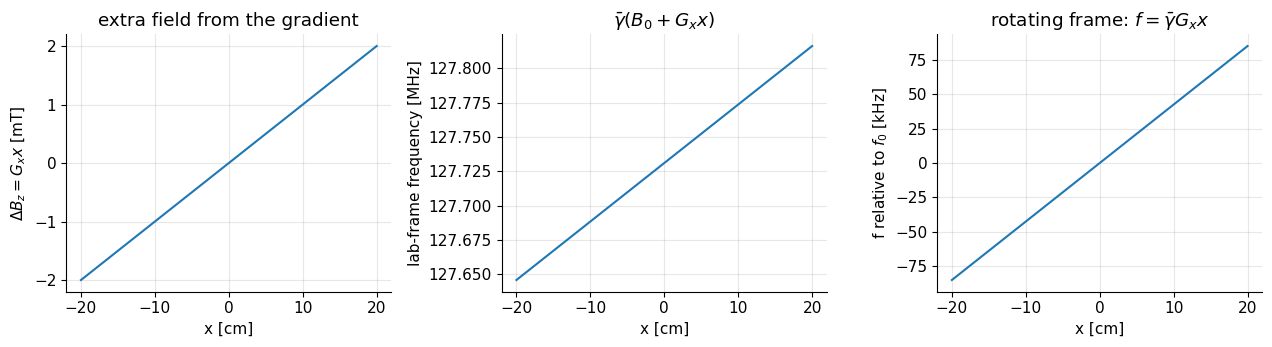

f0 at 3 T = 127.73 MHz
At x = 10 cm the gradient adds 1.0 mT  ->  42.6 kHz extra
Relative change of the field: 333 ppm


In [2]:
B0 = 3.0              # main field [T]
G = 10e-3             # gradient amplitude: 10 mT/m expressed in T/m
x = np.linspace(-0.2, 0.2, 401)          # position along x [m] (a 40 cm wide body)

Bz = B0 + G * x                          # total z-field [T]
f_lab = mt.GAMMA_BAR * Bz                # lab-frame precession frequency [Hz]
f_rot = mt.GAMMA_BAR * G * x             # rotating-frame frequency (relative to f0) [Hz]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(x * 100, (Bz - B0) * 1e3)
ax[0].set(xlabel="x [cm]", ylabel=r"$\Delta B_z = G_x x$ [mT]", title="extra field from the gradient")
ax[1].plot(x * 100, f_lab / 1e6)
ax[1].set(xlabel="x [cm]", ylabel="lab-frame frequency [MHz]", title=r"$\bar\gamma(B_0+G_x x)$")
ax[2].plot(x * 100, f_rot / 1e3)
ax[2].set(xlabel="x [cm]", ylabel="f relative to $f_0$ [kHz]", title=r"rotating frame: $f=\bar\gamma G_x x$")
plt.tight_layout(); plt.show()

print(f"f0 at 3 T = {mt.larmor_frequency(B0)/1e6:.2f} MHz")
print(f"At x = 10 cm the gradient adds {G*0.10*1e3:.1f} mT  ->  {mt.GAMMA_BAR*G*0.10/1e3:.1f} kHz extra")
print(f"Relative change of the field: {G*0.10/B0*1e6:.0f} ppm")

Interpretation: across a 40 cm body the gradient changes the field by only ±2 mT (≈ ±670 ppm of $B_0$), but in the rotating frame this is a frequency spread of ±85 kHz — easily measurable by the receiver.

> **🔧 Engineering reality:** clinical gradient coils deliver 40–80 mT/m (research "connectome" systems up to 300 mT/m) and can change at 100–200 T/m/s (**slew rate**). Driving them takes amplifiers of ~1–2 kV and several hundred amperes. Limits come from amplifier power, coil heating, **peripheral nerve stimulation** by the rapidly changing field ($dB/dt$), and acoustic noise (the "banging"). Gradients are also never perfectly linear far from isocenter, which causes geometric distortion that scanners correct in software. See [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) and [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb).

### Why we need gradients at all

The MRI signal is an *accumulation over space* of all the transverse magnetization the receive coil can "see":

$$ s(t) = \int M_{xy}(\vec r, t)\, d\vec r $$

In words: the coil voltage is (proportional to) the sum of all precessing magnetization — one number per time point, no matter how big the object.

where $s(t)$ is the demodulated signal (arbitrary units; we ignore the coil sensitivity, which we take as uniform, and all constant factors — see [MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)) and $M_{xy}(\vec r,t)$ the transverse magnetization at $\vec r$.

Without gradients every location precesses at the same frequency, so all contributions add up indistinguishably: there is **no fine spatial information**. (Small RF coils provide some localization because they only see nearby tissue, but on the scale of centimetres; parallel imaging exploits this, see [Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb).) Reconstructing images relies on the Fourier transform to convert the spatial information encoded in frequency back into space; the details follow below and in [K-space](../pass2_deep_dive/F2_K-space.ipynb).

## 2. Frequency and phase encoding, or "FT imaging"

By far the most common way to perform spatial encoding uses so-called **frequency encoding** and **phase encoding**. It is also known as **FT imaging** (or 2DFT / 3DFT imaging), since we reconstruct images with a 2D (or 3D) Fourier transform.

It consists of 2 types of encoding:
1. **Frequency encoding** – one dimension is encoded using a constant gradient applied *during* data acquisition.
2. **Phase encoding** – additional dimensions are encoded using a gradient applied *before* data acquisition. This gradient is incremented from one repetition to the next to provide complete spatial encoding. Phase encoding is applied in 1 dimension for 2D imaging, and in 2 dimensions for 3D imaging (see [Volumetric Imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb)).

In 2D imaging the third dimension, $z$, is handled by **slice selection**: only a thin slab is excited in the first place ([Slice Selection](../pass2_deep_dive/E2_Slice_Selection.ipynb)).

This approach is referred to as a **Cartesian k-space trajectory**, because the data are sampled on a regularly spaced grid in k-space (introduced in [K-space](../pass2_deep_dive/F2_K-space.ipynb)).

## 3. Frequency encoding

After RF excitation, a magnetic field gradient is turned on and the signal is read out *while the gradient is on*. Every position then precesses at its own frequency, so the frequencies present in the signal correspond to spatial locations. By convention, this is applied in the x-direction (in practice it can be rotated to any direction) and called the **readout** gradient, with amplitude $G_{x,r}$:

$$f(x) = \bar \gamma\, G_{x,r}\, x$$

In words: the frequency of the spins at position $x$ is proportional to $x$.

where $f$ [Hz] is the frequency relative to $f_0$, $\bar\gamma$ [Hz/T], $G_{x,r}$ [T/m] the readout gradient amplitude, $x$ [m] the position. Therefore the position is proportional to the frequency:

$$ x = \frac{f}{\bar \gamma\, G_{x,r}}$$

In words: if we find a signal component at frequency $f$, it came from position $f/(\bar\gamma G_{x,r})$. Units check: Hz / (Hz T⁻¹ · T m⁻¹) = m ✓.

### Step-by-step derivation of the frequency-encoded signal

<details><summary><b>📐 Derivation (optional)</b></summary>

1. **Precession in the rotating frame.** A spin in a field offset $\Delta B_z$ precesses at angular frequency $\omega=\gamma\Delta B_z$. With the left-handed (clockwise) convention used throughout these notebooks ([Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)), the complex transverse magnetization obeys the ODE $\frac{d}{dt}M_{xy} = -i\omega M_{xy}$, whose solution is $M_{xy}(t)=M_{xy}(0)\,e^{-i\omega t}$ (a first-order linear ODE, [ODE refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)). We ignore relaxation and field imperfections for now.

2. **Insert the gradient.** With the readout gradient on from $t=0$, $\Delta B_z = G_{x,r}x$, so $\omega(x)=\gamma G_{x,r}x$ and
$$M_{xy}(x,t) = m(x)\, e^{-i\gamma G_{x,r} x t} = m(x)\, e^{-i2\pi \bar\gamma G_{x,r} x t},$$
where $m(x)=M_{xy}(x,0)$ is the transverse magnetization right after excitation (the "image").

3. **Sum over the object.** The coil receives $s(t)=\int M_{xy}(x,t)\,dx$ (in 1D, think of $m(x)$ as already integrated over $y$ and $z$):
$$ s(t) = \int m(x)\, e^{-i2\pi\, (\bar\gamma G_{x,r} t)\, x}\, dx .$$

4. **Recognize a Fourier transform.** The continuous Fourier transform ([RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)) is $\mathcal F\{m\}(k)=\int m(x)e^{-i2\pi kx}dx$. Comparing: $s(t)$ is the Fourier transform of $m$ evaluated at the spatial frequency
$$k_x(t) = \bar\gamma G_{x,r}\, t \quad [\text{m}^{-1}].$$
As time passes, $k_x$ sweeps linearly through spatial frequencies.

5. **Invert.** Sampling $s(t)$ at $t_j = j\Delta t$ gives Fourier samples at $k_j = j\Delta k$ with $\Delta k = \bar\gamma G_{x,r}\Delta t$; an inverse DFT returns $m$ at positions spaced by $\delta = 1/(N_{read}\Delta k)$ over a field of view $FOV_x = 1/\Delta k = 1/(\bar\gamma G_{x,r}\Delta t) = BW_{read}/(\bar\gamma G_{x,r})$ (derived properly in [FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)).

</details>

So from frequency-encoding data alone, a **1D image** (a *projection* of the object onto $x$, i.e. $m$ integrated over $y$ within the slice) can be reconstructed with an inverse Fourier transform.

> **🧭 Intuition:** frequency encoding is like a piano where each key is a position. With the gradient on, the object "plays a chord"; the loudness of each note is the amount of magnetization at that position. A spectrum analyzer (= Fourier transform) tells you how loud each note was.

> **🔁 Refresher:** why is "find the loudness of every frequency" a Fourier transform, and how does the continuous FT relate to the DFT/FFT you know? See [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb).

### Simulation: the frequency-encoded signal of a 1D object

We now *simulate the measurement* directly from physics, without using any Fourier transform for the forward step: we put 4000 small spin packets ("isochromats") along $x$, let each precess at $\bar\gamma G_{x,r}x$, add up their $M_{xy}$ at each ADC sample time, and only then reconstruct with an inverse FFT.

Realistic parameters (the same "design example" is used throughout Parts F and G): $FOV = 240$ mm, $N_{read} = 128$ samples, receiver bandwidth $BW_{read} = 64$ kHz → dwell time $\Delta t = 1/BW_{read} = 15.6$ µs, and the readout gradient that makes the FOV fit into the bandwidth, $G_{x,r} = BW_{read}/(\bar\gamma\,FOV) \approx 6.3$ mT/m.

dwell time = 15.6 us, readout duration = 2.00 ms, G_xr = 6.26 mT/m


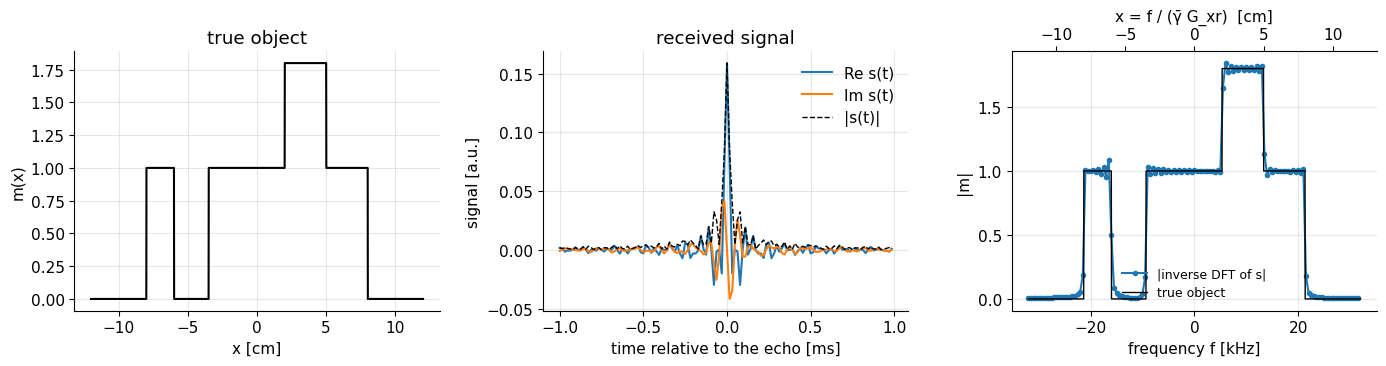

In [3]:
# --- acquisition parameters (SI units) ---
FOV = 0.24            # field of view [m]
N_read = 128          # number of ADC samples
BW_read = 64e3        # total receiver bandwidth [Hz]
dt = 1 / BW_read      # dwell time [s]
G_xr = BW_read / (mt.GAMMA_BAR * FOV)      # readout gradient [T/m]
# ADC sample times measured from the echo (k_x = 0): -T_read/2 ... +T_read/2.
# Negative times are made possible by a negative "prephaser" lobe before the readout (see K-space chapter);
# physically: k_x(t_j) = gamma_bar * G_xr * t_j runs from -k_max to +k_max.
t = (np.arange(N_read) - N_read // 2) * dt     # [s]
print(f"dwell time = {dt*1e6:.1f} us, readout duration = {N_read*dt*1e3:.2f} ms, G_xr = {G_xr*1e3:.2f} mT/m")

# --- a 1D "object": a body (|x|<8 cm) with a bright structure and a dark cavity ---
x_fine = (np.arange(4000) + 0.5) / 4000 * FOV - FOV / 2   # spin positions [m]
dx = FOV / 4000                                            # length represented by one spin packet [m]
m_true = 1.0 * (np.abs(x_fine) < 0.08)
m_true = m_true + 0.8 * ((x_fine > 0.02) & (x_fine < 0.05))     # bright structure
m_true = m_true * ~((x_fine > -0.06) & (x_fine < -0.035))       # dark cavity (no signal)

# --- forward model: sum of all spin packets, each precessing at gamma_bar*G*x (rotating frame) ---
phase = -2 * np.pi * mt.GAMMA_BAR * G_xr * x_fine[None, :] * t[:, None]   # (N_read, N_spins) [rad]
s = (m_true[None, :] * np.exp(1j * phase)).sum(axis=1) * dx               # received signal s(t_j)

# --- reconstruction: centered inverse DFT of the samples ---
dk = mt.GAMMA_BAR * G_xr * dt                      # k-space step [1/m]
# sum_j s_j exp(+i 2 pi k_j x) dk  ==  sqrt(N) * ifftc(s) * dk   (ifftc uses the "ortho" normalization)
profile = np.sqrt(N_read) * mt.ifftc(s) * dk
x_rec = (np.arange(N_read) - N_read // 2) / (N_read * dk)  # reconstructed positions [m]
f_rec = mt.GAMMA_BAR * G_xr * x_rec                         # the corresponding frequencies [Hz]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(x_fine * 100, m_true, "k")
ax[0].set(xlabel="x [cm]", ylabel="m(x)", title="true object")
ax[1].plot(t * 1e3, s.real, label="Re s(t)")
ax[1].plot(t * 1e3, s.imag, label="Im s(t)")
ax[1].plot(t * 1e3, np.abs(s), "k--", lw=1, label="|s(t)|")
ax[1].set(xlabel="time relative to the echo [ms]", ylabel="signal [a.u.]", title="received signal")
ax[1].legend()
ax[2].plot(f_rec / 1e3, np.abs(profile), "o-", ms=3, label="|inverse DFT of s|")
ax2 = ax[2].secondary_xaxis("top", functions=(lambda f: f * 1e3 / (mt.GAMMA_BAR * G_xr) * 100,
                                              lambda xc: xc / 100 * mt.GAMMA_BAR * G_xr / 1e3))
ax2.set_xlabel("x = f / (γ̄ G_xr)  [cm]")
ax[2].plot(mt.GAMMA_BAR * G_xr * x_fine / 1e3, m_true, "k", lw=1, label="true object")
ax[2].set(xlabel="frequency f [kHz]", ylabel="|m|", title="")
ax[2].legend(loc="lower center", fontsize=9)
plt.tight_layout(); plt.show()

Interpretation: the signal itself looks nothing like the object (it is largest at the echo, $t=0$, when all spins are in phase, and oscillates and decays as they fan out on either side), but its spectrum *is* the object: the frequency axis (bottom) converts into position (top) through $x=f/(\bar\gamma G_{x,r})$. The reconstruction has 128 pixels of $240/128 = 1.9$ mm, so the sharp edges are slightly smoothed.

> **🔧 Engineering reality:** the object must fit into the receiver bandwidth: it spans the frequencies $\bar\gamma G_{x,r}\cdot(\pm L/2)$, with $L$ its length. Anything outside $\pm BW_{read}/2$ is either filtered out by the receiver's anti-aliasing filter or folds back ("wraps"). Because extra readout samples cost no extra scan time, scanners routinely **oversample** 2× in the readout direction and discard the extra FOV afterwards ([FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)).

> **⚠️ Common confusion:** real scanners do not start sampling at $t=0$ of the readout gradient. A negative "prephaser" lobe first moves $k_x$ to $-k_{max}$, and the signal peak (the **gradient echo**) occurs in the middle of the readout, at $TE$. This gives symmetric coverage of positive and negative spatial frequencies. We postpone the details to [K-space](../pass2_deep_dive/F2_K-space.ipynb); the simulation above already samples symmetrically around the echo. (If you only sampled $k_x \ge 0$, i.e. started at $t=0$ of the readout gradient, a plain inverse DFT of a real, continuous object would give a visibly corrupted profile with a large spurious background: the DFT silently treats the samples at $k_x > k_{max}$ as if they were negative frequencies. Try it by changing `t` to `np.arange(N_read) * dt`.)

### What the spins do during frequency encoding (port of the original animation)

The original notebook visualizes the transverse magnetization of a 9×9 grid of spin packets as little arrows (the arrow is $M_{xy}$ drawn in the complex plane, $M_x$ to the right, $M_y$ up). During the readout gradient, the arrows at larger $|x|$ rotate faster; arrows in the same column stay identical. We show six snapshots instead of a movie. (Units here are normalized, as in the original: positions in "pixels" from −4 to 4, $k$ in cycles/pixel.)

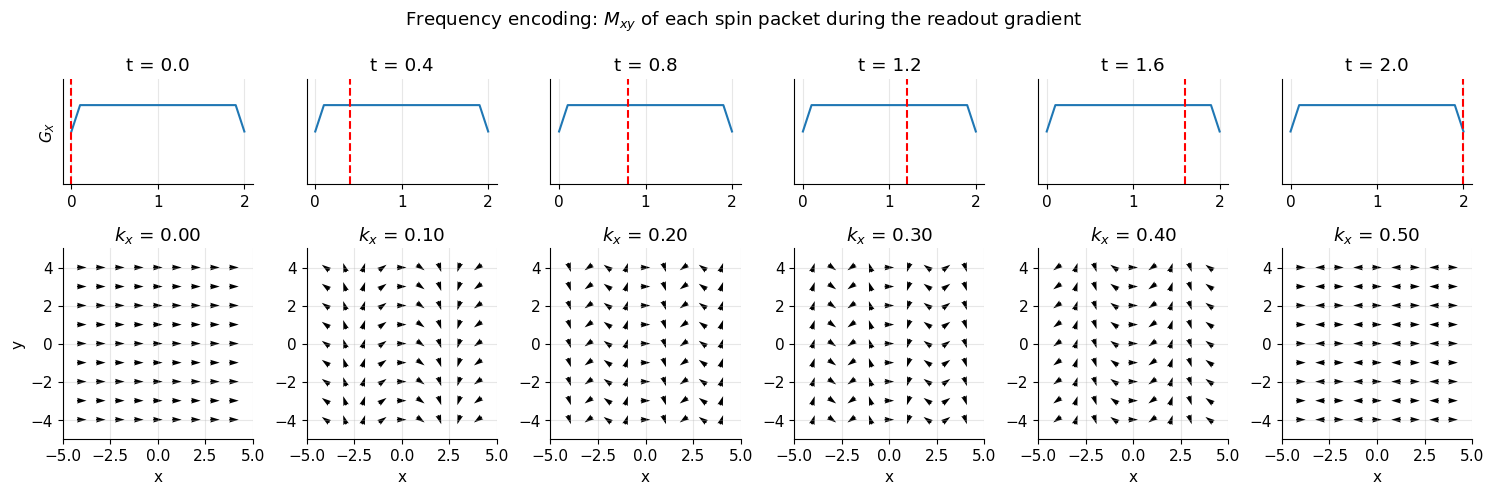

In [4]:
N = 8
xg = np.arange(-N / 2, N / 2 + 1)
xg, yg = np.meshgrid(xg, xg)               # spin-packet grid (positions in "pixels")
Mxy0 = np.ones((N + 1, N + 1), complex)    # uniform transverse magnetization after excitation
Splot = 0.5                                # arrow length scale

kFE = 1 / 2      # final k reached by the readout gradient [cycles/pixel]
Tfe = 2.0        # duration of frequency encoding (normalized time units)
dtn = 0.1        # time step (normalized)

fig, axs = plt.subplots(2, 6, figsize=(15, 5), gridspec_kw={"height_ratios": [1, 2.6]})
t_axis = np.arange(0, Tfe + dtn, dtn)
grad = np.concatenate([[0], np.ones(len(t_axis) - 2) * kFE / (Tfe / dtn), [0]])
for j, tfe in enumerate(np.linspace(0, 1, 6) * Tfe):
    kx_now = kFE * tfe / Tfe                       # k reached at this time
    Mxy = Mxy0 * np.exp(-1j * 2 * np.pi * kx_now * xg)   # our sign convention: e^{-i 2 pi k x}
    axs[0, j].plot(t_axis, grad); axs[0, j].axvline(tfe, color="r", ls="--")
    axs[0, j].set(ylim=(-0.05, 0.05), title=f"t = {tfe:.1f}", yticks=[])
    if j == 0: axs[0, j].set_ylabel("$G_X$")
    axs[1, j].quiver(xg - Mxy.real * Splot / 2, yg - Mxy.imag * Splot / 2, Mxy.real, Mxy.imag,
                     scale=10 / Splot, width=0.012)
    axs[1, j].set(xlim=(-N / 2 - 1, N / 2 + 1), ylim=(-N / 2 - 1, N / 2 + 1), aspect="equal",
                  xlabel="x", title=f"$k_x$ = {kx_now:.2f}")
axs[1, 0].set_ylabel("y")
fig.suptitle(r"Frequency encoding: $M_{xy}$ of each spin packet during the readout gradient")
plt.tight_layout(); plt.show()

Interpretation: at the end ($k_x = 1/2$ cycle per pixel) neighbouring columns differ by 180°: the phase now varies by one full cycle every two pixels — the finest pattern a pixel grid can represent. Each snapshot is a different "stripe pattern" of phase along $x$, and the signal at that moment is the sum of all arrows.

## 4. Phase encoding

Frequency encoding can only separate positions along *one* direction: all spins with the same $x$ have the same frequency, whatever their $y$. (If you also switched on $G_y$ during the readout, the frequency would be $\bar\gamma(G_xx+G_yy)$ — constant along *tilted* lines, so the ambiguity is just rotated; this is the idea behind radial imaging, see [K-space](../pass2_deep_dive/F2_K-space.ipynb).) The second (and optionally third) dimension is therefore encoded differently: by **phase encoding**.

### Step 1 – a short gradient pulse leaves a phase "memory"

After excitation but *before* the readout, a gradient $G_y$ is switched on for a short time $t_y$ and then off again. While it is on, spins at position $y$ precess at the extra angular frequency $\gamma G_y y$. When it is switched off, all spins precess at the same frequency again — but they **keep the phase they accumulated**:

$$\phi(y) = -\gamma\, G_y\, t_y\, y = -2\pi\,\bar\gamma\, G_y t_y\, y$$

In words: after the lobe, the phase of $M_{xy}$ varies linearly along $y$; the slope is set by the gradient **area** $G_y t_y$. The minus sign comes from the clockwise precession convention ($M_{xy}\propto e^{-i\omega t}$).

where $\phi$ [rad] is the phase, $\gamma$ [rad s⁻¹ T⁻¹], $G_y$ [T/m] the phase-encoding amplitude, $t_y$ [s] the lobe duration, $y$ [m] the position.

Strictly, the phase is $-\gamma y\int G_y(\tau)d\tau$, so only the **area** matters, not the shape. We check this with a Bloch simulation (using `mt.bloch_simulate`, rotating frame, no relaxation) for three lobes of equal area: a strong short one, a weak long one, and a realistic trapezoid.

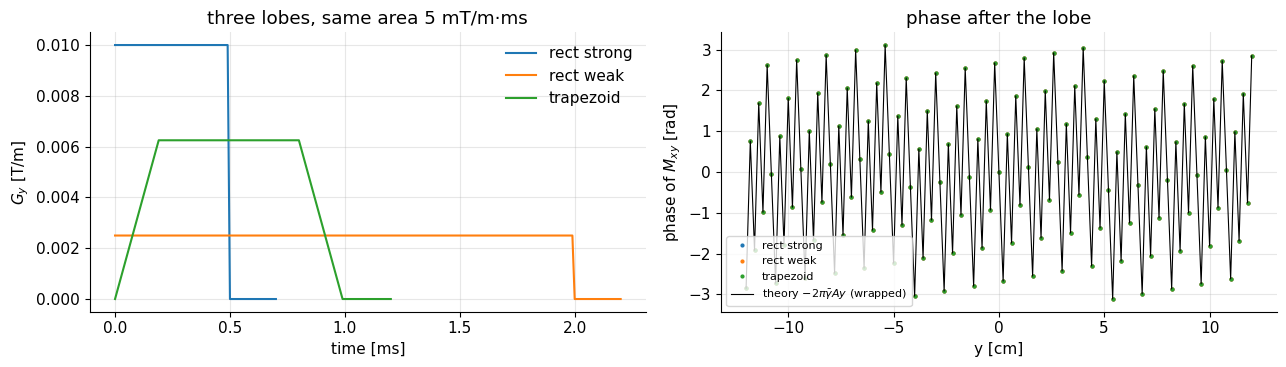

In [5]:
dt_sim = 10e-6                                   # simulation step [s]
y_pos = np.linspace(-0.12, 0.12, 121)            # spin positions along y [m]
r = np.stack([np.zeros_like(y_pos), y_pos, np.zeros_like(y_pos)], axis=-1)
area = 5e-6                                      # target gradient area [T s / m] (= 5 mT/m * 1 ms)

def lobe(shape):
    """Gradient waveform (Nt, 3) with G only on the y channel; all lobes have area `area`."""
    if shape == "rect strong":   g = np.full(50, area / (50 * dt_sim))          # 0.5 ms
    elif shape == "rect weak":   g = np.full(200, area / (200 * dt_sim))        # 2 ms
    else:                                                                     # trapezoid
        ramp = np.linspace(0, 1, 20); g = np.concatenate([ramp, np.ones(60), ramp[::-1]])
        g = g * area / (g.sum() * dt_sim)
    G = np.zeros((len(g) + 20, 3)); G[:len(g), 1] = g     # 0.2 ms of "gradient off" afterwards
    return G

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for shape in ["rect strong", "rect weak", "trapezoid"]:
    G = lobe(shape)
    tt, M = mt.bloch_simulate(G=G, r=r, dt=dt_sim, M_init=(1.0, 0.0, 0.0))   # start with M_xy = 1
    ax[0].plot(tt * 1e3, G[:, 1].tolist() + [0] , label=shape)
    Mxy_end = M[-1, :, 0] + 1j * M[-1, :, 1]
    ax[1].plot(y_pos * 100, np.angle(Mxy_end), ".", ms=4, label=shape)
theory = np.angle(np.exp(-1j * 2 * np.pi * mt.GAMMA_BAR * area * y_pos))
ax[1].plot(y_pos * 100, theory, "k-", lw=0.8, label=r"theory $-2\pi\bar\gamma A y$ (wrapped)")
ax[0].set(xlabel="time [ms]", ylabel="$G_y$ [T/m]", title="three lobes, same area 5 mT/m·ms"); ax[0].legend()
ax[1].set(xlabel="y [cm]", ylabel="phase of $M_{xy}$ [rad]", title="phase after the lobe"); ax[1].legend(fontsize=8, loc="lower left", frameon=True)
plt.tight_layout(); plt.show()

Interpretation: all three lobes produce exactly the same (wrapped) linear phase ramp along $y$: about $\bar\gamma A \cdot 0.24\,\text{m} \approx 51$ cycles across 24 cm. Only the gradient area $A=\int G_y\,dt$ counts. (This is also why a phase-encoding step "is equivalent to taking a sample of a frequency-encoding gradient": the phase after area $A$ is the same as after frequency-encoding for a time $A/G$.)

### Step 2 – one measurement gives only one number per stripe pattern

After the phase-encoding lobe, the magnetization is $M_{xy}(y) = m(y)\,e^{-i2\pi k_y y}$ with $k_y = \bar\gamma G_y t_y$. The signal the coil receives at that moment (consider for now a 1D object along $y$) is

$$ s = \int m(y)\, e^{-i2\pi k_y y}\, dy $$

In words: the coil measures the overlap of the object with one complex "stripe pattern" of spatial frequency $k_y$ — **a single Fourier coefficient** of $m(y)$.

where $k_y$ [m⁻¹] counts how many cycles of phase twist there are per metre along $y$.

Unlike in frequency encoding, the phase pattern in $y$ does **not keep changing** during the readout (the $G_y$ lobe is over). So one excitation gives only *one* value of $k_y$. To reconstruct $N_{PE}$ pixels along $y$ we need $N_{PE}$ different Fourier coefficients, i.e. $N_{PE}$ **separate excitations**, each with a different $G_y$ amplitude. Each excitation costs one repetition time $TR$ (we must wait for the magnetization to recover, see [Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)). This is the fundamental reason why MRI is slow:

* **frequency direction:** $N_{read}$ samples in one readout of a few ms (cheap),
* **phase direction:** $N_{PE}$ repetitions of the whole experiment (expensive): $T_{scan} = TR\cdot N_{PE}\cdot NEX$.

> **🧭 Intuition:** phase encoding asks the object $N_{PE}$ different questions: "how much of you looks like a pattern with 0 stripes? with 1 stripe across the FOV? with 2? …". Each answer is one number, and each question requires a fresh excitation. A Fourier transform then assembles the answers into an image.

### Step 3 – the phase of the $n$-th phase-encoding step

The original writes the phase of step $n$ tersely as $\Phi(n) = \gamma(-G_{yp}+(n-1)G_{yi})t_y y$. Let us unpack it.

In step $n$ ($n = 1, 2, \dots, N_{PE}$) the phase-encoding amplitude is

$$ G_y^{(n)} = -G_{y,PE} + (n-1)\,G_{yi} $$

In words: start at the most negative amplitude $-G_{y,PE}$ and go up by the same increment $G_{yi}$ in every repetition.

where
* $n$ is the step (repetition) number, $N_{PE}$ the total number of steps,
* $G_{y,PE}$ [T/m] the largest (absolute) phase-encoding amplitude (the original and the sequence figure call it $G_{yp}$),
* $G_{yi}$ [T/m] the amplitude increment between consecutive steps.

The last step must reach $+G_{y,PE}$: $-G_{y,PE}+(N_{PE}-1)G_{yi} = G_{y,PE}$, hence

$$ 2\,G_{y,PE} = (N_{PE}-1)\,G_{yi} $$

In words: the full range of amplitudes, $2G_{y,PE}$, is divided into $N_{PE}-1$ equal increments.

The lobe of duration $t_y$ [s] then leaves the phase (magnitude written as in the original, $\gamma$ in rad s⁻¹ T⁻¹)

$$ \Phi(n) = \gamma\,\big(-G_{y,PE} + (n-1)\,G_{yi}\big)\,t_y\,y = \gamma\, G_y^{(n)} t_y\, y $$

In words: the phase is (angular gyromagnetic ratio) × (gradient area of step $n$) × (position). With our clockwise sign convention the actual phase of $M_{xy}$ is $\phi_n(y) = -\Phi(n)$; the sign only mirrors the image and is irrelevant for the magnitude.

Written as a spatial frequency:

$$ k_y^{(n)} = \bar\gamma\, G_y^{(n)}\, t_y, \qquad \Delta k_y = k_y^{(n+1)}-k_y^{(n)} = \bar\gamma\, G_{yi}\, t_y $$

In words: each step moves $k_y$ by the same amount $\Delta k_y$, so the phase-encoding steps sample $k_y$ on a regular grid from $-k_{y,max}=-\bar\gamma G_{y,PE}t_y$ to $+k_{y,max}$.

> **⚠️ Common confusion:** with this symmetric formula and an **even** $N_{PE}$ (e.g. 256), $k_y=0$ is *not* sampled: the steps sit at $\pm\Delta k_y/2, \pm 3\Delta k_y/2, \dots$. Scanners instead use $G_y^{(n)} = (n-1-N_{PE}/2)\,G_{yi}$, i.e. $k_y = -\tfrac{N_{PE}}{2}\Delta k_y, \dots, (\tfrac{N_{PE}}{2}-1)\Delta k_y$, which includes $k_y = 0$ and matches the index convention of the centered FFT (`mt.ifft2c`). The two choices differ by a half-step shift in k-space, which by the Fourier shift theorem is only a linear phase across the image ([Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb)); the magnitude image is the same.

**Numbers** (design example): $FOV_y = 240$ mm, $N_{PE} = 256$, $t_y = 1$ ms. The k-space spacing must be $\Delta k_y = 1/FOV_y$ ([FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)):

In [6]:
FOV_y = 0.24      # [m]
N_PE = 256
t_y = 1e-3        # phase-encoding lobe duration [s]

dky = 1 / FOV_y                              # required k-space step [1/m]
G_yi = dky / (mt.GAMMA_BAR * t_y)            # amplitude increment [T/m]
G_yPE = (N_PE - 1) / 2 * G_yi                # largest amplitude [T/m]
ky_max = mt.GAMMA_BAR * G_yPE * t_y          # [1/m]
print(f"Delta k_y = {dky:.2f} 1/m   ->  G_yi   = {G_yi*1e3:.4f} mT/m")
print(f"G_y,PE    = {G_yPE*1e3:.2f} mT/m   (well below a 40 mT/m gradient limit)")
print(f"k_y,max   = {ky_max:.0f} 1/m  -> finest stripe wavelength 1/k_max = {1/ky_max*1e3:.2f} mm")
n = np.arange(1, N_PE + 1)
Gy_n = -G_yPE + (n - 1) * G_yi
print("first/last amplitudes [mT/m]:", np.round(Gy_n[[0, 1, 2, -1]] * 1e3, 4))

Delta k_y = 4.17 1/m   ->  G_yi   = 0.0979 mT/m
G_y,PE    = 12.48 mT/m   (well below a 40 mT/m gradient limit)
k_y,max   = 531 1/m  -> finest stripe wavelength 1/k_max = 1.88 mm
first/last amplitudes [mT/m]: [-12.4774 -12.3795 -12.2817  12.4774]


Interpretation: tiny increments (0.1 mT/m) and a modest maximum (12.5 mT/m) are enough. Shortening $t_y$ (to shorten TE) requires proportionally larger amplitudes; that is where the gradient hardware limits show up.

### Step 4 – the stripes: the $M_{xy}$ phase pattern of each phase-encoding step

The port of the original code below shows the arrows of the 9×9 grid at the end of each of the 9 phase-encoding steps (normalized units: $k_y$ from −1/2 to +1/2 cycles/pixel). Below it, a finer grid (64×64) shows the same thing as **stripes**: $\mathrm{Re}\{M_{xy}\}=M_x$ in gray and the phase as color (this is the `image_phase` mode of the original `spatial_encoding_Mxy_illustration.m`).

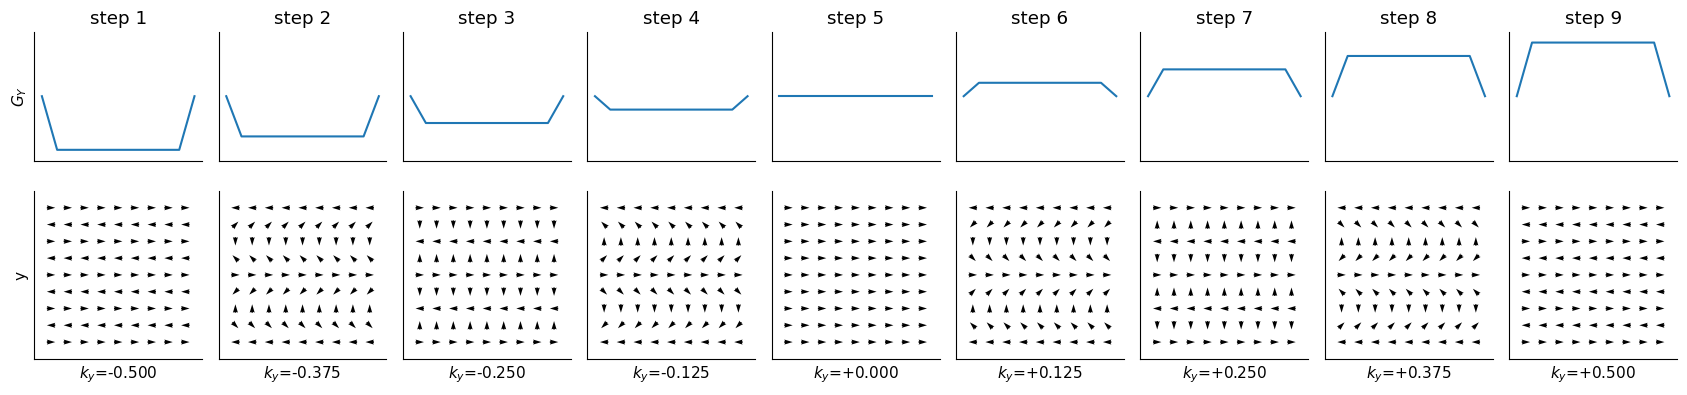

In [7]:
kPE = np.arange(-N / 2, N / 2 + 1) / N      # 9 phase-encoding steps [cycles/pixel]
Tpe, dtn = 1.0, 0.1
t_axis = np.arange(0, Tpe + dtn, dtn)

fig, axs = plt.subplots(2, 9, figsize=(17, 4.4), gridspec_kw={"height_ratios": [1, 2.2]})
for Ipe, kpe in enumerate(kPE):
    Mxy = Mxy0 * np.exp(-1j * 2 * np.pi * kpe * yg)          # phase after the full PE lobe
    gradw = np.concatenate([[0], np.ones(len(t_axis) - 2) * kpe / (Tpe / dtn), [0]])
    axs[0, Ipe].plot(t_axis, gradw); axs[0, Ipe].set(ylim=(-0.06, 0.06), yticks=[], xticks=[],
                                                      title=f"step {Ipe+1}")
    axs[1, Ipe].quiver(xg - Mxy.real * Splot / 2, yg - Mxy.imag * Splot / 2, Mxy.real, Mxy.imag,
                       scale=10 / Splot, width=0.02)
    axs[1, Ipe].set(xlim=(-5, 5), ylim=(-5, 5), aspect="equal", xticks=[], yticks=[],
                    xlabel=f"$k_y$={kpe:+.3f}")
axs[0, 0].set_ylabel("$G_Y$"); axs[1, 0].set_ylabel("y")
plt.tight_layout(); plt.show()

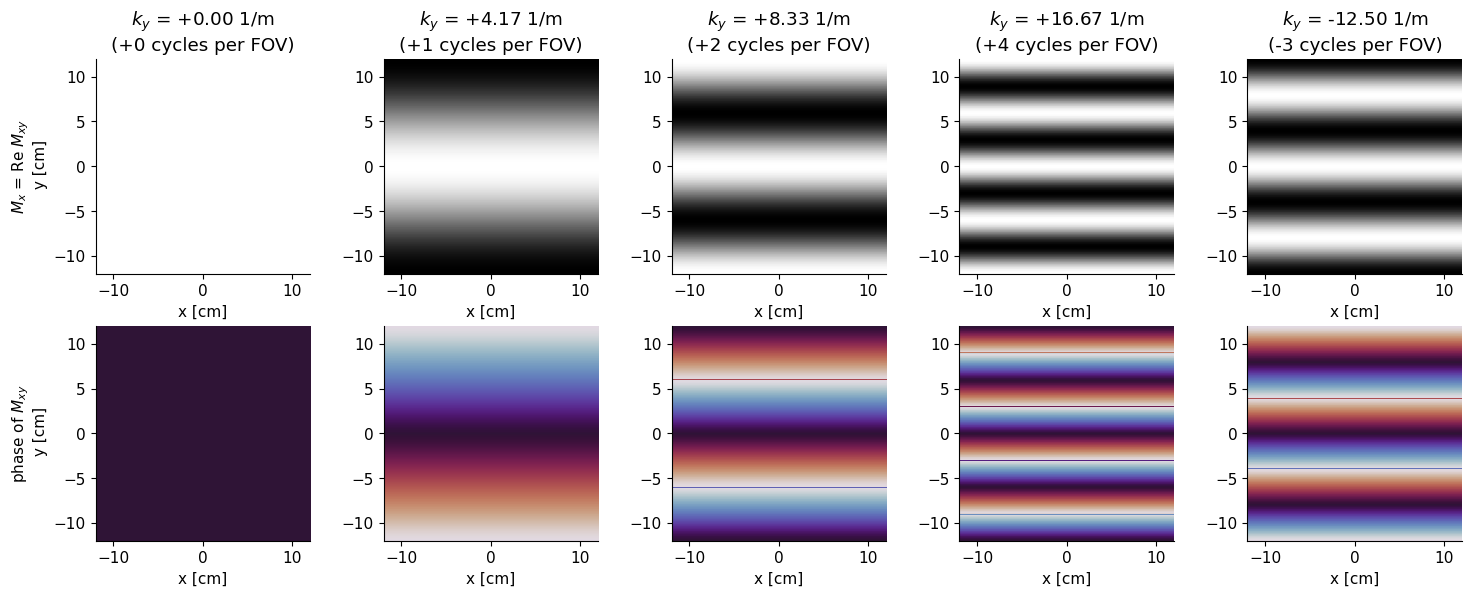

In [8]:
# finer grid: stripes of M_x and of the phase, for a few phase-encoding steps (SI units)
xf = np.linspace(-FOV / 2, FOV / 2, 128)
XF, YF = np.meshgrid(xf, xf)
dky8 = 1 / FOV                              # Delta k for FOV = 24 cm
fig, axs = plt.subplots(2, 5, figsize=(15, 6))
for j, n_cycles in enumerate([0, 1, 2, 4, -3]):
    ky = n_cycles * dky8                    # spatial frequency [1/m]
    Mxy = np.exp(-1j * 2 * np.pi * ky * YF)   # after the PE lobe (uniform object, m = 1)
    axs[0, j].imshow(Mxy.real, cmap="gray", vmin=-1, vmax=1, origin="lower",
                     extent=[-12, 12, -12, 12])
    axs[0, j].set_title(f"$k_y$ = {ky:+.2f} 1/m\n({n_cycles:+d} cycles per FOV)")
    axs[1, j].imshow(np.angle(Mxy), cmap="twilight", vmin=-np.pi, vmax=np.pi, origin="lower",
                     extent=[-12, 12, -12, 12])
    for a in axs[:, j]: a.grid(False); a.set_xlabel("x [cm]")
axs[0, 0].set_ylabel("$M_x$ = Re $M_{xy}$\n y [cm]"); axs[1, 0].set_ylabel("phase of $M_{xy}$\n y [cm]")
plt.tight_layout(); plt.show()

Interpretation: phase-encoding step $n$ writes a stripe pattern with (index − center) cycles across the FOV into the magnetization. Positive and negative $k_y$ give stripes with the *same spacing* but opposite direction of phase winding (visible in the color, invisible in $M_x$ alone — that is why we need the complex signal, i.e. quadrature detection). The signal of that step measures how much the object "resembles" this stripe pattern. This is exactly the 2D Fourier basis of [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb).

## 5. Frequency and phase encoding together

The following simulation from the original book shows how first the phase-encoding gradient ($G_Y$) creates phase variation in $y$, and then during the frequency-encoding gradient ($G_X$) the magnetizations rotate at frequencies depending on their $x$ position:

![Frequency and phase encoding: M_xy arrows during the phase-encoding lobe and then the readout gradient, repeated for each phase-encoding step](../images/frequency_phase_encoding-simple-Mxy.gif)

Instead of viewing the arrows, we can also visualize this encoding as a map of the phase of the transverse magnetization:

![Frequency and phase encoding: map of the phase of M_xy, which forms tilted stripes](../images/frequency_phase_encoding-simple-image_phase.gif)

(The original generates these movies with `spatial_encoding_Mxy_illustration.m`; the Python version below produces snapshots of the same thing.)

### Python port of `spatial_encoding_Mxy_illustration.m` (snapshots)

We build the gradient waveforms of one repetition (a phase-encoding lobe, then the readout gradient), integrate them to get the accumulated phase "twist" per metre at every time, and display the phase of $M_{xy}(x,y,t) = e^{-i2\pi(k_x(t)x+k_y(t)y)}$ for a uniform object. The helper `phase_snapshots` is defined here (it is the Python equivalent of `plot_gradient_phase_evolution.m`); the integral $k(t)=\bar\gamma\int_0^t G\,d\tau$ is introduced formally in [K-space](../pass2_deep_dive/F2_K-space.ipynb).

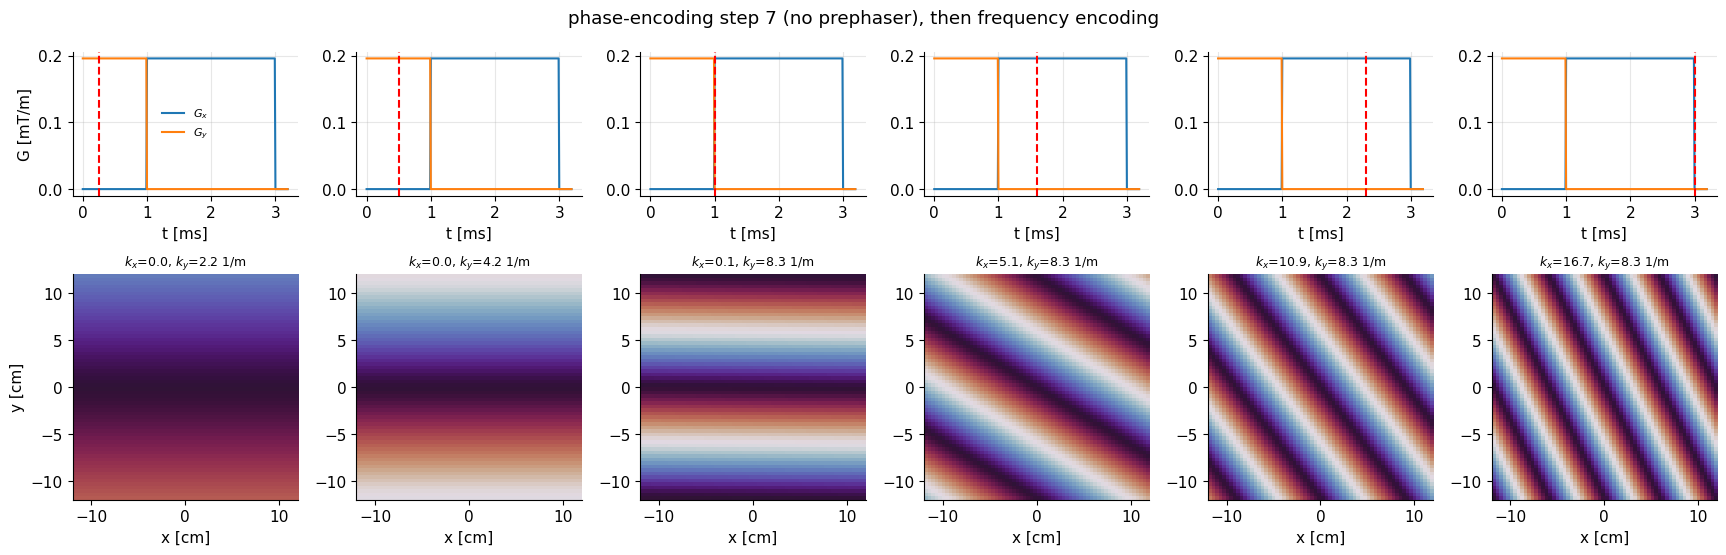

In [9]:
def phase_snapshots(t, Gx, Gy, t_show, FOV=0.24, n_grid=64, title=""):
    """Show the phase of M_xy (uniform object) at the times t_show.

    t, Gx, Gy : arrays (s, T/m, T/m) describing the gradient waveforms
    The accumulated phase is -2*pi*(k_x x + k_y y), with k = gamma_bar * cumulative gradient area.
    """
    dt_ = t[1] - t[0]
    kx = mt.GAMMA_BAR * np.cumsum(Gx) * dt_          # [1/m]
    ky = mt.GAMMA_BAR * np.cumsum(Gy) * dt_
    g = np.linspace(-FOV / 2, FOV / 2, n_grid)
    X, Y = np.meshgrid(g, g)
    fig, axs = plt.subplots(2, len(t_show), figsize=(2.9 * len(t_show), 5.6),
                            gridspec_kw={"height_ratios": [1, 2]})
    for j, ts in enumerate(t_show):
        i = np.argmin(np.abs(t - ts))
        axs[0, j].plot(t * 1e3, Gx * 1e3, label="$G_x$"); axs[0, j].plot(t * 1e3, Gy * 1e3, label="$G_y$")
        axs[0, j].axvline(t[i] * 1e3, color="r", ls="--"); axs[0, j].set_xlabel("t [ms]")
        ph = np.angle(np.exp(-1j * 2 * np.pi * (kx[i] * X + ky[i] * Y)))
        axs[1, j].imshow(ph, cmap="twilight", vmin=-np.pi, vmax=np.pi, origin="lower",
                         extent=[-FOV / 2 * 100, FOV / 2 * 100] * 2)
        axs[1, j].grid(False)
        axs[1, j].set_title(f"$k_x$={kx[i]:.1f}, $k_y$={ky[i]:.1f} 1/m", fontsize=9)
        axs[1, j].set_xlabel("x [cm]")
    axs[0, 0].set_ylabel("G [mT/m]"); axs[0, 0].legend(fontsize=8); axs[1, 0].set_ylabel("y [cm]")
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return kx, ky

# one repetition, low resolution (N = 8 pixels across 24 cm) so the stripes are visible
FOVs, Ns = 0.24, 8
dts = 10e-6
ts = np.arange(0, 3.2e-3, dts)
Tpe_s, Tfe_s = 1e-3, 2e-3
kmax = Ns / 2 / FOVs                                   # [1/m]
n_step = 7                                             # which PE step (1..9) to show
ky_target = (n_step - 1 - Ns / 2) / FOVs               # k_y of this step [1/m]
Gx_s = np.where((ts >= Tpe_s) & (ts < Tpe_s + Tfe_s), kmax / (mt.GAMMA_BAR * Tfe_s), 0.0)
Gy_s = np.where(ts < Tpe_s, ky_target / (mt.GAMMA_BAR * Tpe_s), 0.0)
_ = phase_snapshots(ts, Gx_s, Gy_s, [0.25e-3, 0.5e-3, 1.0e-3, 1.6e-3, 2.3e-3, 3.0e-3],
                    title=f"phase-encoding step {n_step} (no prephaser), then frequency encoding")

Interpretation: during the $G_y$ lobe horizontal stripes appear (phase varies along $y$ only); once $G_x$ is on, the stripes tilt as phase also builds up along $x$. At every instant the magnetization is *one* plane-wave pattern $e^{-i2\pi(k_xx+k_yy)}$, and the signal is the object's overlap with it — one 2D Fourier coefficient.

### The 2D signal and its reconstruction

Combining both encodings, the signal sampled at time $t$ (measured from the start of the readout) in phase-encoding step $n$ is

$$ s_n(t) = \iint m(x,y)\; e^{-i2\pi\left(\bar\gamma G_{x,r} t\; x \;+\; \bar\gamma G_y^{(n)} t_y\; y\right)}\, dx\, dy = M\!\left(k_x(t),\, k_y^{(n)}\right) $$

In words: every ADC sample in every repetition is one value of the 2D Fourier transform of the object, at $k_x = \bar\gamma G_{x,r}t$ (set by the time within the readout) and $k_y = \bar\gamma G_y^{(n)}t_y$ (set by the repetition). Arranging the $N_{PE}\times N_{read}$ samples on a grid and applying a 2D inverse FFT gives the image.

where $M(k_x,k_y)=\mathcal F\{m\}$ here denotes **k-space data** (not magnetization), $m(x,y)$ the transverse magnetization of the slice right after excitation, and all other symbols are as above.

We now simulate a complete (tiny) 2D acquisition: a Shepp–Logan phantom represented by 256×256 spin packets, acquired with $N_{read}=N_{PE}=64$. The forward model is the double sum over all spin packets — computed as two matrix products because the exponential factorizes into an $x$ part and a $y$ part. As promised by the warning above, we use the scanner convention $k = -N/2,\dots,N/2-1$ times $\Delta k$ in both directions (for $k_x$ this needs the prephaser of [K-space](../pass2_deep_dive/F2_K-space.ipynb)).

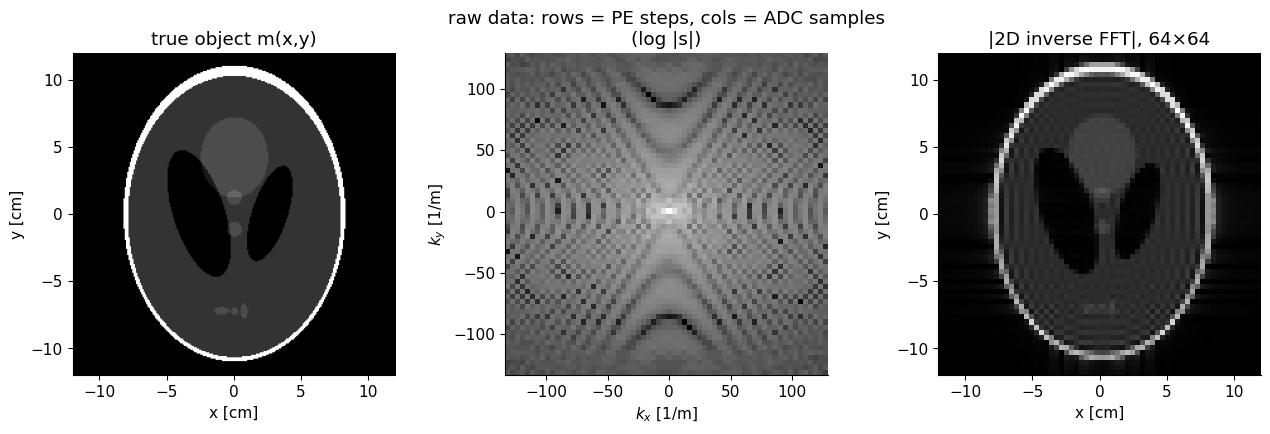

max |recon| = 1.149  (true object max = 1)


In [10]:
Nobj = 256                                    # spin packets per direction (the "true" object)
obj = np.flipud(mt.shepp_logan(Nobj))         # row index increasing with y
pos = (np.arange(Nobj) - Nobj / 2 + 0.5) / Nobj * FOV   # spin-packet positions [m]
dA = (FOV / Nobj) ** 2                        # area per spin packet [m^2]

Nacq = 64                                     # N_read = N_PE = 64
dk = 1 / FOV                                  # [1/m]
kx = (np.arange(Nacq) - Nacq // 2) * dk       # readout samples (time) -> k_x
ky = (np.arange(Nacq) - Nacq // 2) * dk       # phase-encoding steps   -> k_y

# s[n, j] = sum_{y,x} m(x,y) exp(-i2pi ky_n y) exp(-i2pi kx_j x) dA
Ey = np.exp(-1j * 2 * np.pi * np.outer(ky, pos))     # (N_PE, Nobj)
Ex = np.exp(-1j * 2 * np.pi * np.outer(kx, pos))     # (N_read, Nobj)
s2d = Ey @ obj @ Ex.T * dA                           # (N_PE, N_read) raw data

recon = Nacq * mt.ifft2c(s2d) * dk**2                # ~ sum s exp(+i2pi k r) dk^2 (see F3 for scaling)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ext = [-FOV / 2 * 100, FOV / 2 * 100] * 2
ax[0].imshow(obj, cmap="gray", origin="lower", extent=ext); ax[0].set_title("true object m(x,y)")
ax[1].imshow(np.log10(np.abs(s2d) + 1e-9), cmap="gray", origin="lower",
             extent=[kx[0], kx[-1], ky[0], ky[-1]])
ax[1].set(title="raw data: rows = PE steps, cols = ADC samples\n(log |s|)", xlabel="$k_x$ [1/m]",
          ylabel="$k_y$ [1/m]")
ax[2].imshow(np.abs(recon), cmap="gray", origin="lower", extent=ext); ax[2].set_title("|2D inverse FFT|, 64×64")
for a in (ax[0], ax[2]): a.set(xlabel="x [cm]", ylabel="y [cm]")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
print("max |recon| =", np.abs(recon).max().round(3), " (true object max = 1)")

Interpretation: the raw data are brightest in the middle (low spatial frequencies carry most of the signal) and the 2D inverse FFT of the simulated physical measurement recovers the phantom at 64×64 resolution (3.75 mm pixels; fine details are blurred — see [FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)). Each row of the raw-data matrix took one TR to acquire.

## 6. The 2D FT imaging pulse sequence

The following pulse sequence diagram from the original shows a Cartesian 2D FT sequence with frequency and phase encoding, including relevant amplitudes and durations. A **gradient-echo** sequence is shown; the principles extend directly to a spin-echo sequence ([Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)). Idealized rectangular gradients are shown for simplicity.

![Cartesian 2D FT gradient-echo sequence with labelled amplitudes and durations](../images/pulse_sequence-diagram-Cartesian-parameters.png)

How to read it (the figure's labels → our notation):

| Row | What happens | Labels |
|---|---|---|
| RF | slice-selective excitation, flip angle $\theta$, duration $T_{rf}$, time–bandwidth product $TBW_{rf}$ | |
| $G_Z$ | slice-select gradient $G_{z,SS}$ during the RF pulse, followed by a negative **rephasing** lobe that undoes the phase spread across the slice thickness; a spoiler at the end of TR | $G_{Z,SS}$ |
| $G_X$ | negative **prephaser** (moves $k_x$ to $-k_{max}$), then the readout gradient $G_{x,r}$ during the ADC; a rewinder/spoiler at the end | figure: $G_{xr}$ = our $G_{x,r}$ |
| $G_Y$ | phase-encoding lobe of duration $t_y$, a different amplitude (dashed "table") in each TR between $-G_{y,PE}$ and $+G_{y,PE}$ in steps of $G_{yi}$; often a **rewinder** with opposite area at the end of TR | figure: $G_{yp}$ = our $G_{y,PE}$ |
| DAQ | ADC samples $N_{read}$ points spaced by the dwell time, duration $T_{read}$; the echo (center of k-space in $x$) is at $TE$ | figure: $\Delta T_s=1/RBW$ = our $\Delta t = 1/BW_{read}$ |
| bracket | the whole block is repeated $N_{TR}$ times ($=N_{PE}\cdot NEX$ without acceleration), once every $TR$ | |

Below we draw the same sequence in Python with realistic trapezoidal gradients (the design example: FOV 240 mm, $N_{read}=N_{PE}=256$, $BW_{read}=64$ kHz, slew rate 150 T/m/s). The phase-encoding lobe is drawn for several steps on top of each other.

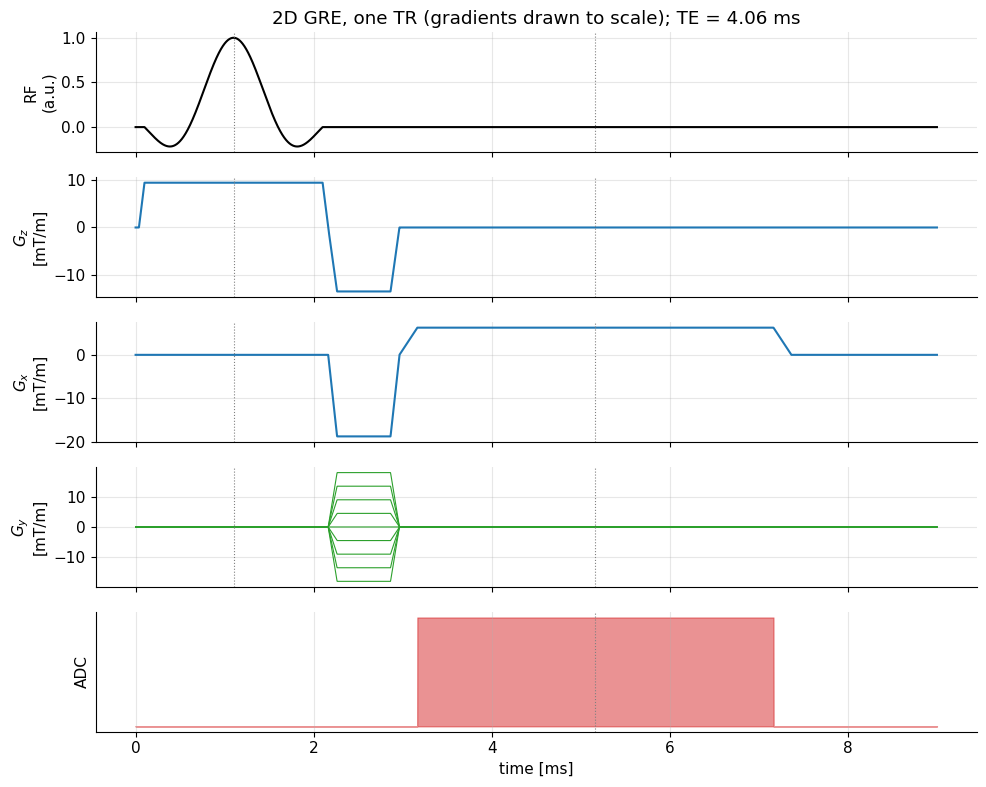

G_z,SS = 9.4 mT/m, G_x,r = 6.26 mT/m, T_read = 4.0 ms, max PE amplitude = 17.9 mT/m


In [11]:
def trapezoid(t, t_start, flat, ramp, amp):
    """Trapezoidal gradient [T/m] on time axis t [s]: linear ramp, flat top, linear ramp down."""
    g = np.zeros_like(t)
    t1, t2, t3 = t_start + ramp, t_start + ramp + flat, t_start + 2 * ramp + flat
    up = (t >= t_start) & (t < t1); g[up] = amp * (t[up] - t_start) / ramp
    g[(t >= t1) & (t < t2)] = amp
    dn = (t >= t2) & (t < t3); g[dn] = amp * (t3 - t[dn]) / ramp
    return g

dt_d = 2e-6
td = np.arange(0, 9e-3, dt_d)
SR = 150.0                                   # slew rate [T/m/s]
# RF: 2 ms sinc (TBW = 4) centred at 1.1 ms
T_rf, TBW = 2e-3, 4
t_rf0 = 0.1e-3
rf = np.where((td >= t_rf0) & (td < t_rf0 + T_rf), np.sinc(TBW * ((td - t_rf0) / T_rf - 0.5)), 0)
# slice select: 5 mm slice -> G = (TBW/T_rf) / (gamma_bar * dz)
dz = 5e-3
G_ss = (TBW / T_rf) / (mt.GAMMA_BAR * dz)
ramp_ss = G_ss / SR
Gz = trapezoid(td, t_rf0 - ramp_ss, T_rf, ramp_ss, G_ss)
A_reph = -0.5 * G_ss * T_rf                     # rephaser: minus half the plateau area
t_after = t_rf0 + T_rf + ramp_ss
Gz += trapezoid(td, t_after, 0.6e-3, 0.1e-3, A_reph / 0.7e-3)
# readout: 256 samples at 64 kHz -> 4 ms, G_xr from FOV
Nrd, BW, FOVd = 256, 64e3, 0.24
T_read = Nrd / BW
G_x = BW / (mt.GAMMA_BAR * FOVd)
ramp_x = 0.2e-3
t_pre = t_after                                  # prephaser simultaneous with rephaser & PE
A_pre = -G_x * (T_read / 2 + ramp_x / 2)          # moves k_x to -k_max at the first ADC sample
Gx = trapezoid(td, t_pre, 0.6e-3, 0.1e-3, A_pre / 0.7e-3)
t_ro = t_pre + 0.8e-3
Gx += trapezoid(td, t_ro, T_read, ramp_x, G_x)
t_adc0 = t_ro + ramp_x
adc = (td >= t_adc0) & (td < t_adc0 + T_read)
TE = t_adc0 + T_read / 2 - (t_rf0 + T_rf / 2)
# phase encoding: area for k_y = (n - N/2) / FOV, here a few of the 256 steps
fig, axs = plt.subplots(5, 1, figsize=(10, 8), sharex=True)
axs[0].plot(td * 1e3, rf, "k"); axs[0].set_ylabel("RF\n(a.u.)")
axs[1].plot(td * 1e3, Gz * 1e3); axs[1].set_ylabel("$G_z$\n[mT/m]")
axs[2].plot(td * 1e3, Gx * 1e3); axs[2].set_ylabel("$G_x$\n[mT/m]")
for nn in np.linspace(0, Nrd, 9):
    A_pe = (nn - Nrd / 2) / FOVd / mt.GAMMA_BAR             # required area [T s/m]
    axs[3].plot(td * 1e3, trapezoid(td, t_pre, 0.6e-3, 0.1e-3, A_pe / 0.7e-3) * 1e3, "C2", lw=0.8)
axs[3].set_ylabel("$G_y$\n[mT/m]")
axs[4].fill_between(td * 1e3, adc, color="C3", alpha=0.5); axs[4].set_ylabel("ADC"); axs[4].set_yticks([])
axs[4].set_xlabel("time [ms]")
for a in axs[:4]: a.axvline((t_rf0 + T_rf / 2) * 1e3, color="gray", ls=":", lw=0.8)
for a in axs: a.axvline((t_rf0 + T_rf / 2 + TE) * 1e3, color="gray", ls=":", lw=0.8)
axs[0].set_title(f"2D GRE, one TR (gradients drawn to scale); TE = {TE*1e3:.2f} ms")
plt.tight_layout(); plt.show()
print(f"G_z,SS = {G_ss*1e3:.1f} mT/m, G_x,r = {G_x*1e3:.2f} mT/m, T_read = {T_read*1e3:.1f} ms, "
      f"max PE amplitude = {(Nrd/2)/FOVd/mt.GAMMA_BAR/0.7e-3*1e3:.1f} mT/m")

Interpretation: the prephaser, slice rephaser and phase-encoding lobe all fit into the same ~0.8 ms window, which sets the minimum TE (here ≈ 4 ms, printed in the title). The phase-encoding table (green) is the only thing that changes from TR to TR.

**Scan time.** Each TR acquires one line; without acceleration

$$T_{scan} = TR \cdot N_{PE} \cdot NEX$$

In words: scan time = (time per repetition) × (number of phase-encoding lines) × (number of averages). With $TR = 500$ ms, $N_{PE}=256$, $NEX = 1$: $T_{scan}=128$ s. With a fast GRE, $TR=8$ ms: 2 s. (Details and trade-offs: [Cartesian Image Characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb).)

> **🔧 Engineering reality — which direction to phase encode?** Because each phase-encoding line costs a TR, the phase-encoding direction is usually put along the *shorter* dimension of the anatomy (so fewer lines are needed for a given FOV), and readout along the longer one, where oversampling is free. Motion during the acquisition corrupts the phase-encoding direction most (lines acquired seconds apart are inconsistent), so motion ghosts appear along the phase-encoding direction ([Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)). Conversely, chemical-shift and off-resonance displacement appear along the readout direction, where frequency = position.

> **🔧 Engineering reality — spin echo.** In a spin-echo version the 180° refocusing pulse sits between excitation and readout, the prephaser has the *same* polarity as the readout (the 180° pulse negates the accumulated phase), and TE is typically 10–100 ms; see [K-space](../pass2_deep_dive/F2_K-space.ipynb) and [Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb).

### Try it yourself (interactive)

Pick a phase-encoding step and watch the stripes it writes into $M_{xy}$ and the value of the signal for the phantom (widget output is not stored in the saved notebook; the static figures above show the default case).

In [12]:
try:
    from ipywidgets import interact, IntSlider
    def show_step(n_cycles_y=3, n_cycles_x=0):
        kyv, kxv = n_cycles_y / FOV, n_cycles_x / FOV
        Xp, Yp = np.meshgrid(pos, pos)
        pattern = np.exp(-1j * 2 * np.pi * (kxv * Xp + kyv * Yp))
        sig = np.sum(obj * pattern) * dA
        fig, ax = plt.subplots(1, 2, figsize=(9, 4))
        ax[0].imshow(pattern.real, cmap="gray", origin="lower", extent=ext); ax[0].set_title("Re of stripe pattern")
        ax[1].imshow(obj * pattern.real, cmap="gray", origin="lower", extent=ext)
        ax[1].set_title(f"object × pattern; signal = {sig.real:.4f}{sig.imag:+.4f}i")
        for a in ax: a.grid(False)
        plt.show()
    interact(show_step, n_cycles_y=IntSlider(3, -32, 32), n_cycles_x=IntSlider(0, -32, 32))
except ImportError:
    print("ipywidgets not available")

interactive(children=(IntSlider(value=3, description='n_cycles_y', max=32, min=-32), IntSlider(value=0, descri…

## Key takeaways

* A gradient makes $B_z$, and hence the rotating-frame precession frequency, a linear function of position: $f=\bar\gamma\,\vec G\cdot\vec r$ (e.g. 10 mT/m → 42.6 kHz at 10 cm).
* **Frequency encoding:** with $G_{x,r}$ on during the readout, $x = f/(\bar\gamma G_{x,r})$; the signal is the Fourier transform of the object at $k_x=\bar\gamma G_{x,r}t$, so a whole line of k-space is acquired in one readout.
* **Phase encoding:** a gradient lobe before the readout leaves a phase $\propto$ (gradient area) × position; only the area $\int G\,dt$ matters.
* Step $n$ uses $G_y^{(n)}=-G_{y,PE}+(n-1)G_{yi}$, giving $k_y^{(n)}=\bar\gamma G_y^{(n)}t_y$ with spacing $\Delta k_y = \bar\gamma G_{yi}t_y$; $2G_{y,PE}=(N_{PE}-1)G_{yi}$. Scanners use $k_y=-N/2\ldots N/2-1$ times $\Delta k_y$ so that $k_y=0$ is sampled.
* One excitation yields one phase-encoding value, so $N_{PE}$ repetitions are needed: $T_{scan}=TR\cdot N_{PE}\cdot NEX$. This is why MRI is slow and why motion artifacts appear along the phase-encoding direction.
* Every sample of a 2DFT acquisition is one 2D Fourier coefficient $M(k_x,k_y)$ of the object; a 2D inverse FFT reconstructs the image.

## Check your understanding

1. At 1.5 T with $G_{x,r} = 20$ mT/m, what is the frequency (relative to $f_0$) of spins at $x = -5$ cm? And what position corresponds to a signal component at +17 kHz?

<details><summary>Answer</summary>

$f = \bar\gamma G_{x,r} x = 42.58\times10^6 \cdot 0.02 \cdot (-0.05) \approx -42.6$ kHz. (The field strength $B_0$ does not enter: in the rotating frame only the gradient's contribution remains.) $x = f/(\bar\gamma G_{x,r}) = 17000/(42.58\times10^6\cdot0.02) \approx 2.0$ cm.

</details>

2. Why can't we simply use frequency encoding in both $x$ and $y$ at the same time?

<details><summary>Answer</summary>

With both gradients on during the readout, the frequency is $\bar\gamma(G_xx+G_yy)$: all points on a line $G_xx+G_yy=\text{const}$ share the same frequency. We would only measure a projection along a tilted direction. A different encoding (phase), or many such projections at different angles (radial imaging), is needed to resolve the second dimension.

</details>

3. A phase-encoding lobe of 15 mT/m lasting 0.6 ms and a lobe of 9 mT/m lasting 1 ms: do they encode the same $k_y$? What is it?

<details><summary>Answer</summary>

Yes — both have area 9 µT·s/m (= 9 mT/m·ms); the phase depends only on the area. $k_y=\bar\gamma\cdot\text{area} = 42.58\times10^6\cdot 9\times10^{-6} \approx 383$ m⁻¹ (≈ 92 cycles across a 24 cm FOV).

</details>

4. With $N_{PE}=128$, $FOV_y=200$ mm and $t_y=0.8$ ms, compute $G_{yi}$ and $G_{y,PE}$ (symmetric formula).

<details><summary>Answer</summary>

$\Delta k_y = 1/0.2 = 5$ m⁻¹, $G_{yi} = \Delta k_y/(\bar\gamma t_y) = 5/(42.58\times10^6\cdot 0.8\times10^{-3}) \approx 0.147$ mT/m, $G_{y,PE} = (N_{PE}-1)G_{yi}/2 \approx 9.3$ mT/m.

</details>

5. A spin-echo scan has TR = 600 ms, $N_{PE} = 192$, $N_{read} = 256$, NEX = 2. How long does it take? Does doubling $N_{read}$ change this?

<details><summary>Answer</summary>

$T_{scan} = 0.6 \cdot 192 \cdot 2 = 230$ s ≈ 3.8 min. Doubling $N_{read}$ does **not** change the scan time as long as the longer readout still fits into the TR — readout samples are acquired within each TR; only phase-encoding lines (and averages) multiply the TR.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Spatial Encoding".
Changes: added full derivations of frequency and phase encoding with every symbol defined, physics-based Python simulations (1D frequency-encoded signal, equal-area lobes with Bloch simulation, stripe patterns, full 2D acquisition), a Python port of `spatial_encoding_Mxy_illustration.m`, a to-scale sequence diagram with realistic numbers, and a note on the even-$N_{PE}$ $k_y=0$ issue; fixed typos ("also known FT imaging", "phase of the next magnetization") and made the phase sign convention explicit.*